<a href="https://colab.research.google.com/github/francji1/01NAEX/blob/main/code/01NAEX_Ex05.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01NAEX - Exercise 05: The $2^k$ factorial design

Data and exercises come from D. C. Montgomery: *Design and Analysis of Experiments*, 8th edition, Chapter 6.
Problem numbers follow the 8th edition.

## Learning goals

* Estimate the effects of a $2^k$ design from the table of plus and minus signs and relate them to the ANOVA and to the
  regression coefficients in coded variables (effect $= 2\hat\beta$).
* Fit the full model, refine it, test the lack of fit of the reduced model against the pure error and respect the hierarchy principle.
* Convert the model between coded and natural variables and draw response surface, contour and interaction plots.
* Compute standard errors and confidence intervals of the effects and use them to plan the number of replicates.
* Generate a randomized $2^k$ design in Python.

## Setup

Run this cell first. Besides the standard imports it defines helper functions used below:

* `effects_2k()` - contrasts, effects, sums of squares and coded coefficients of a balanced (replicated) $2^k$ design, computed
  directly from the table of signs.
* `design_2k()` - a $2^k$ design in standard (Yates) order with $n$ replicates and a random run order.
* `residual_plots()` - normal Q-Q plot of the residuals, residuals versus fitted values and versus each factor, Shapiro-Wilk test.

In [1]:
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.graphics.factorplots import interaction_plot

URL = "https://raw.githubusercontent.com/francji1/01NAEX/main/data/"


def effects_2k(data, response, factors):
    """Contrasts, effects, sums of squares and coded coefficients of a balanced 2^k design.

    `factors` are columns coded -1/+1 (main effects in this order: A, B, C, ...). Rows are in standard order
    (A, B, AB, C, AC, BC, ABC, ...) and are named as in statsmodels formulas ("A:B").
    """
    k = len(factors)
    n = len(data) // 2**k
    rows = []
    for i in range(1, 2**k):
        members = [factors[j] for j in range(k) if i >> j & 1]
        sign = data[members].prod(axis=1)
        contrast = (sign * data[response]).sum()
        rows.append({"term": ":".join(members), "contrast": contrast,
                     "effect": contrast / (n * 2**(k - 1)), "SS": contrast**2 / (n * 2**k)})
    table = pd.DataFrame(rows).set_index("term")
    table["coef"] = table["effect"] / 2
    return table


def design_2k(k, n_rep=1, names="ABCDEFGH", seed=None):
    """2^k factorial design in standard order, n_rep replicates and a random run order (column `run`)."""
    runs = itertools.product([-1, 1], repeat=k)
    std = pd.DataFrame([r[::-1] for r in runs], columns=list(names[:k]))      # the first factor changes fastest
    design = pd.concat([std] * n_rep, ignore_index=True)
    design.insert(0, "std_order", np.tile(np.arange(1, 2**k + 1), n_rep))
    design["rep"] = np.repeat(np.arange(1, n_rep + 1), 2**k)
    rng = np.random.default_rng(seed)
    design["run"] = rng.permutation(len(design)) + 1
    return design


def residual_plots(model, data, factors):
    """Q-Q plot, residuals vs fitted values and vs each factor; Shapiro-Wilk test of the residuals."""
    res, fit = model.resid, model.fittedvalues
    fig, axes = plt.subplots(1, 2 + len(factors), figsize=(3.6 * (2 + len(factors)), 3.3))
    sm.qqplot(res, line="s", ax=axes[0])
    axes[0].set_title("Normal Q-Q plot")
    axes[1].scatter(fit, res)
    axes[1].axhline(0, color="red", ls="--")
    axes[1].set(xlabel="fitted", ylabel="residual", title="Residuals vs fitted")
    for ax, f in zip(axes[2:], factors):
        ax.scatter(data[f], res)
        ax.axhline(0, color="red", ls="--")
        ax.set(xlabel=f, title=f"Residuals vs {f}")
    plt.tight_layout()
    plt.show()
    print("Shapiro-Wilk on residuals:", stats.shapiro(res))

## 1. Lecture example: chemical process ($2^2$ design)

Montgomery, Section 6.2: the effect of the reactant concentration (factor $A$: 15 and 25 %) and of the amount of catalyst
(factor $B$: 1 and 2 pounds) on the yield of a chemical process; $n = 3$ replicates, 12 runs in random order.

`yield` is a Python keyword, so a formula `yield ~ ...` does not work. We rename the column to `y`
(the alternative is to quote it in the formula: `Q("yield") ~ ...`).

In [2]:
chem = pd.read_csv(URL + "yield.txt", sep=r"\s+").rename(columns={"yield": "y"})
chem["A"] = chem["reactant"].map({"low": -1, "high": 1})
chem["B"] = chem["catalyst"].map({"low": -1, "high": 1})

# treatment totals (1), a, b, ab
totals = chem.groupby(["B", "A"])["y"].sum()
totals.index = ["(1)", "a", "b", "ab"]
print(totals)
chem.pivot_table(index="catalyst", columns="reactant", values="y", aggfunc=list)

(1)     80
a      100
b       60
ab      90
Name: y, dtype: int64


reactant,high,low
catalyst,,
high,"[31, 30, 29]","[18, 19, 23]"
low,"[36, 32, 32]","[28, 25, 27]"


### Effects from the treatment totals

$A = \frac{1}{2n}[ab + a - b - (1)]$, $B = \frac{1}{2n}[ab + b - a - (1)]$, $AB = \frac{1}{2n}[ab + (1) - a - b]$,
$SS = \text{Contrast}^2 / (4n)$.

In [3]:
one, a, b, ab = totals
n = 3
contrasts = {"A": ab + a - b - one, "B": ab + b - a - one, "A:B": ab + one - a - b}
for name, c in contrasts.items():
    print(f"{name:4s} contrast = {c:4d}, effect = {c / (2 * n):6.3f}, SS = {c**2 / (4 * n):7.3f}")

# the same with the helper function (works for any k)
effects_2k(chem, "y", ["A", "B"])

A    contrast =   50, effect =  8.333, SS = 208.333
B    contrast =  -30, effect = -5.000, SS =  75.000
A:B  contrast =   10, effect =  1.667, SS =   8.333


,contrast,effect,SS,coef
term,,,,
A,50,8.333333,208.333333,4.166667
B,-30,-5.000000,75.000000,-2.500000
A:B,10,1.666667,8.333333,0.833333


### ANOVA and model refinement

In [4]:
m_full = smf.ols("y ~ A * B", data=chem).fit()
display(sm.stats.anova_lm(m_full, typ=2))

m_red = smf.ols("y ~ A + B", data=chem).fit()
display(sm.stats.anova_lm(m_red, typ=2))

# F-test of the dropped interaction (the same as the F-test of AB in the full model)
sm.stats.anova_lm(m_red, m_full)

,sum_sq,df,F,PR(>F)
A,208.333333,1.0,53.191489,0.000084
B,75.000000,1.0,19.148936,0.002362
A:B,8.333333,1.0,2.127660,0.182776
Residual,31.333333,8.0,NaN,NaN


,sum_sq,df,F,PR(>F)
A,208.333333,1.0,47.268908,0.000073
B,75.000000,1.0,17.016807,0.002578
Residual,39.666667,9.0,NaN,NaN


,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,9.0,39.666667,0.0,NaN,NaN,NaN
1,8.0,31.333333,1.0,8.333333,2.12766,0.182776


The concentration ($F_0 = 53.2$, $p < 0.001$) and the catalyst ($F_0 = 19.1$, $p = 0.002$) are significant, the interaction is not
($p = 0.18$). Coding the factors as $\pm 1$ numbers or as categories (`C(reactant)`) gives the same ANOVA.

### Regression model in coded and natural variables

In [5]:
print(m_full.summary().tables[1])
print(m_red.summary().tables[1])
print("effects / 2:", (effects_2k(chem, "y", ["A", "B"])["coef"]).round(4).to_dict())

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     27.5000      0.571     48.135      0.000      26.183      28.817
A              4.1667      0.571      7.293      0.000       2.849       5.484
B             -2.5000      0.571     -4.376      0.002      -3.817      -1.183
A:B            0.8333      0.571      1.459      0.183      -0.484       2.151
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     27.5000      0.606     45.377      0.000      26.129      28.871
A              4.1667      0.606      6.875      0.000       2.796       5.538
B             -2.5000      0.606     -4.125      0.003      -3.871      -1.129
effects / 2: {'A': 4.1667, 'B': -2.5, 'A:B': 0.8333}


The coefficients are one half of the effects and they do not change when $AB$ is removed (orthogonal design); only
$\hat\sigma$ and the standard errors change. The fitted reduced model is $\hat y = 27.5 + 4.167\,x_1 - 2.5\,x_2$.

In natural units: $x_1 = (Conc - 20)/5$, $x_2 = (Cat - 1.5)/0.5$.

In [6]:
chem["conc"] = 20 + 5 * chem["A"]
chem["cat"] = 1.5 + 0.5 * chem["B"]
m_nat = smf.ols("y ~ conc + cat", data=chem).fit()
print(m_nat.params)

# the same fitted values
print("same predictions:", np.allclose(m_nat.fittedvalues, m_red.fittedvalues))

Intercept    18.333333
conc          0.833333
cat          -5.000000
dtype: float64
same predictions: True


$\hat y = 18.33 + 0.833\,Conc - 5.0\,Cat$. The coefficients now depend on the units (per % and per pound).

### Response surface and contour plot

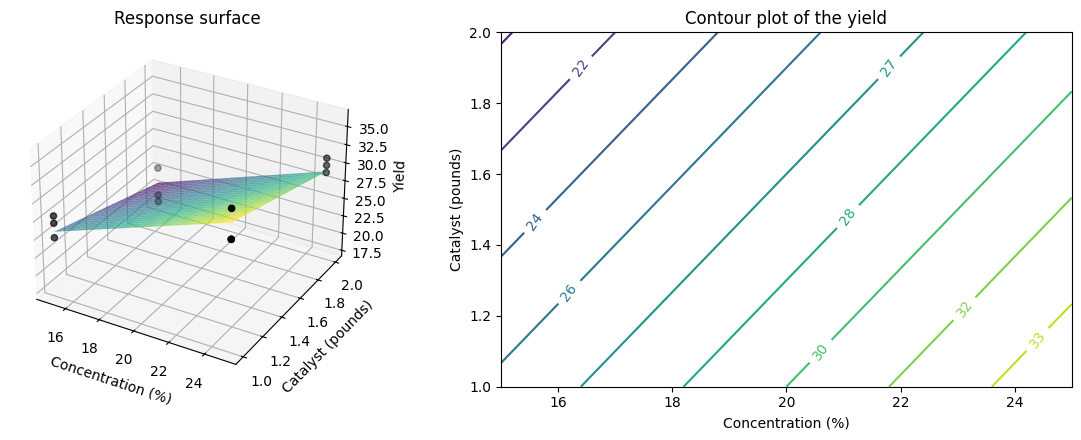

In [7]:
g1, g2 = np.meshgrid(np.linspace(15, 25, 51), np.linspace(1, 2, 51))
grid = pd.DataFrame({"conc": g1.ravel(), "cat": g2.ravel()})
z = m_nat.predict(grid).to_numpy().reshape(g1.shape)

fig = plt.figure(figsize=(12, 4.5))
ax1 = fig.add_subplot(1, 2, 1, projection="3d")
ax1.plot_surface(g1, g2, z, cmap="viridis", alpha=0.7)
ax1.scatter(chem["conc"], chem["cat"], chem["y"], color="k")
ax1.set(xlabel="Concentration (%)", ylabel="Catalyst (pounds)", zlabel="Yield", title="Response surface")
ax2 = fig.add_subplot(1, 2, 2)
cs = ax2.contour(g1, g2, z, levels=10, cmap="viridis")
ax2.clabel(cs, fmt="%.0f")
ax2.set(xlabel="Concentration (%)", ylabel="Catalyst (pounds)", title="Contour plot of the yield")
plt.tight_layout(); plt.show()

The first-order model is a plane: the contour lines are parallel straight lines. The yield increases towards high
concentration and low catalyst; the highest predicted yield inside the region is at $Conc = 25$ %, $Cat = 1$ pound.
Outside the region (and for possible curvature) the model says nothing.

### Model adequacy

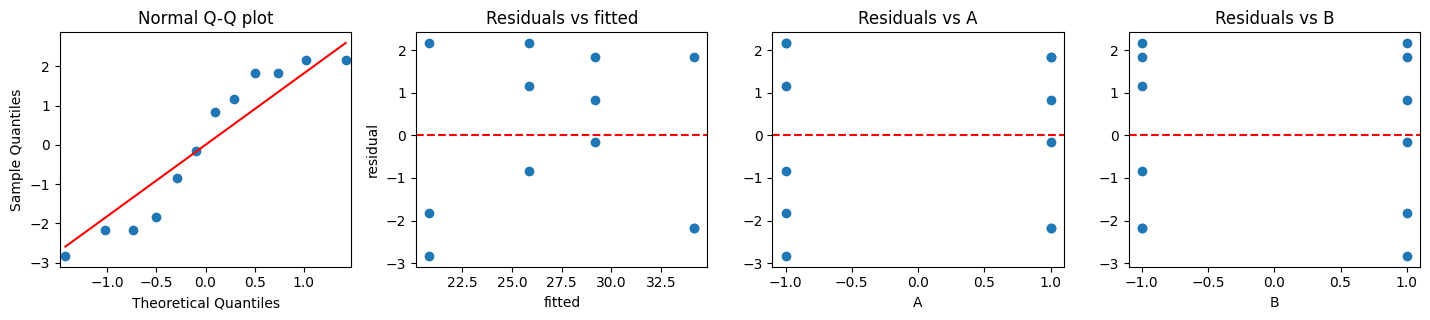

Shapiro-Wilk on residuals: ShapiroResult(statistic=np.float64(0.8817860959872293), pvalue=np.float64(0.09239123833656315))


In [8]:
residual_plots(m_red, chem, ["A", "B"])

## 2. Lecture example: plasma etch experiment ($2^3$ design)

Montgomery, Example 6.1: etch rate of silicon nitride (Å/min) in a single-wafer plasma etching tool. Factors: $A$ = gap between
the electrodes (0.8 and 1.2 cm), $B$ = C$_2$F$_6$ gas flow (125 and 200 SCCM), $C$ = RF power (275 and 325 W); $n = 2$ replicates.
The file has one row per treatment combination and the replicates in columns `R1`, `R2`; we reshape it to the long format.

In [9]:
plasma = pd.read_csv(URL + "plasma.txt", sep=r"\s+")
display(plasma.assign(total=plasma["R1"] + plasma["R2"]))

etch = plasma.melt(id_vars=["Run", "A", "B", "C"], value_vars=["R1", "R2"], var_name="rep", value_name="etch")
etch.head()

,Run,A,B,C,R1,R2,total
0,1,-1,-1,-1,550,604,1154
1,2,1,-1,-1,669,650,1319
2,3,-1,1,-1,633,601,1234
3,4,1,1,-1,642,635,1277
4,5,-1,-1,1,1037,1052,2089
5,6,1,-1,1,749,868,1617
6,7,-1,1,1,1075,1063,2138
7,8,1,1,1,729,860,1589


,Run,A,B,C,rep,etch
0,1,-1,-1,-1,R1,550
1,2,1,-1,-1,R1,669
2,3,-1,1,-1,R1,633
3,4,1,1,-1,R1,642
4,5,-1,-1,1,R1,1037


Note: the total of the treatment combination $bc$ is $1075 + 1063 = 2138$; the value 2178 printed in Table 6.4 of the book is a misprint.

### Effects from the table of signs

In [10]:
eff = effects_2k(etch, "etch", ["A", "B", "C"])
display(eff)

# the table of signs is the design matrix of the full coded model
full = smf.ols("etch ~ A * B * C", data=etch).fit()
X = pd.DataFrame(full.model.exog, columns=full.model.exog_names)
print(X.drop_duplicates().to_string(index=False))
print("X'X =\n", X.T @ X)

,contrast,effect,SS,coef
term,,,,
A,-813,-101.625,41310.5625,-50.8125
B,59,7.375,217.5625,3.6875
A:B,-199,-24.875,2475.0625,-12.4375
C,2449,306.125,374850.0625,153.0625
A:C,-1229,-153.625,94402.5625,-76.8125
B:C,-17,-2.125,18.0625,-1.0625
A:B:C,45,5.625,126.5625,2.8125


 Intercept    A    B  A:B    C  A:C  B:C  A:B:C
       1.0 -1.0 -1.0  1.0 -1.0  1.0  1.0   -1.0
       1.0  1.0 -1.0 -1.0 -1.0 -1.0  1.0    1.0
       1.0 -1.0  1.0 -1.0 -1.0  1.0 -1.0    1.0
       1.0  1.0  1.0  1.0 -1.0 -1.0 -1.0   -1.0
       1.0 -1.0 -1.0  1.0  1.0 -1.0 -1.0    1.0
       1.0  1.0 -1.0 -1.0  1.0  1.0 -1.0   -1.0
       1.0 -1.0  1.0 -1.0  1.0 -1.0  1.0   -1.0
       1.0  1.0  1.0  1.0  1.0  1.0  1.0    1.0
X'X =
            Intercept     A     B   A:B     C   A:C   B:C  A:B:C
Intercept       16.0   0.0   0.0   0.0   0.0   0.0   0.0    0.0
A                0.0  16.0   0.0   0.0   0.0   0.0   0.0    0.0
B                0.0   0.0  16.0   0.0   0.0   0.0   0.0    0.0
A:B              0.0   0.0   0.0  16.0   0.0   0.0   0.0    0.0
C                0.0   0.0   0.0   0.0  16.0   0.0   0.0    0.0
A:C              0.0   0.0   0.0   0.0   0.0  16.0   0.0    0.0
B:C              0.0   0.0   0.0   0.0   0.0   0.0  16.0    0.0
A:B:C            0.0   0.0   0.0   0.0   0.0   0.

The columns of the table of signs are orthogonal ($X^TX = 16\,I$). The large effects are $C$ (power, $+306$), $AC$ ($-154$)
and $A$ (gap, $-102$).

### ANOVA of the full model

In [11]:
sm.stats.anova_lm(full, typ=2)

,sum_sq,df,F,PR(>F)
A,41310.5625,1.0,18.339364,0.002679
B,217.5625,1.0,0.096584,0.763911
A:B,2475.0625,1.0,1.098776,0.325168
C,374850.0625,1.0,166.410505,0.000001
A:C,94402.5625,1.0,41.908965,0.000193
B:C,18.0625,1.0,0.008019,0.930849
A:B:C,126.5625,1.0,0.056186,0.818586
Residual,18020.5000,8.0,NaN,NaN


$A$, $C$ and $AC$ are significant; $B$ and all interactions with $B$ are not. With replicates, $MS_E = 2252.6$ (8 df) of the full
model is the **pure error**.

### Reduced model and lack of fit

In [12]:
red = smf.ols("etch ~ A * C", data=etch).fit()
display(sm.stats.anova_lm(red, typ=2))

# lack of fit of the reduced model = the dropped terms B, AB, BC, ABC, tested against the pure error
display(sm.stats.anova_lm(red, full))
print(red.summary().tables[1])
print(f"R2 = {red.rsquared:.4f}, adj. R2 = {red.rsquared_adj:.4f}  (full model: {full.rsquared:.4f}, {full.rsquared_adj:.4f})")

,sum_sq,df,F,PR(>F)
A,41310.5625,1.0,23.767029,3.816422e-04
C,374850.0625,1.0,215.660881,4.951261e-09
A:C,94402.5625,1.0,54.312222,8.620836e-06
Residual,20857.7500,12.0,NaN,NaN


,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,12.0,20857.75,0.0,NaN,NaN,NaN
1,8.0,18020.50,4.0,2837.25,0.314891,0.860354


                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    776.0625     10.423     74.458      0.000     753.353     798.772
A            -50.8125     10.423     -4.875      0.000     -73.522     -28.103
C            153.0625     10.423     14.685      0.000     130.353     175.772
A:C          -76.8125     10.423     -7.370      0.000     -99.522     -54.103
R2 = 0.9608, adj. R2 = 0.9509  (full model: 0.9661, 0.9364)


The lack of fit is not significant ($F_0 = 0.31$, $p = 0.86$): the reduced model
$\hat y = 776.06 - 50.81\,x_1 + 153.06\,x_3 - 76.81\,x_1x_3$ is adequate. It explains $R^2 = 96.1$ % of the variability;
$R^2_{adj}$ increased from 0.936 to 0.951.

### Standard errors and confidence intervals of the effects

$V(\text{Effect}) = \sigma^2 / (n2^{k-2})$; the intervals of the effects are twice the intervals of the coded coefficients.

In [13]:
n, k = 2, 3
se_eff = np.sqrt(full.mse_resid / (n * 2**(k - 2)))
t = stats.t.ppf(0.975, full.df_resid)
print(f"se(effect) = {se_eff:.2f}, t = {t:.3f}, half-width = {t * se_eff:.2f}")

ci = 2 * full.conf_int().drop("Intercept")
ci.columns = ["lower", "upper"]
ci.insert(0, "effect", 2 * full.params.drop("Intercept"))
ci.round(2)

se(effect) = 23.73, t = 2.306, half-width = 54.72


,effect,lower,upper
A,-101.63,-156.35,-46.90
B,7.37,-47.35,62.10
A:B,-24.88,-79.60,29.85
C,306.13,251.40,360.85
A:C,-153.62,-208.35,-98.90
B:C,-2.12,-56.85,52.60
A:B:C,5.62,-49.10,60.35


Only the intervals of $A$, $C$ and $AC$ exclude zero, in agreement with the ANOVA.

### Main effects and interaction plots

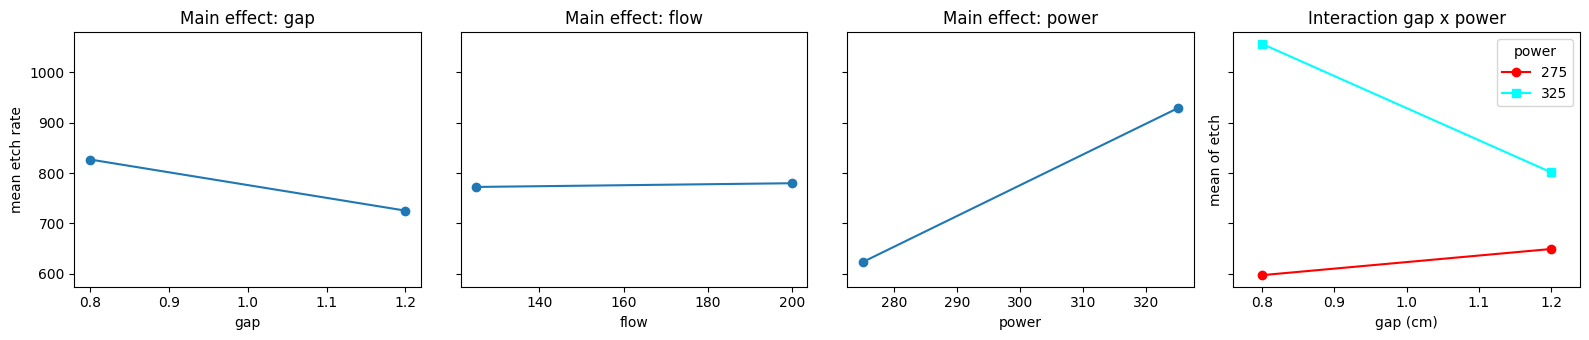

gap,0.8,1.2
power,,
275,597.00,649.0
325,1056.75,801.5


In [14]:
etch["gap"] = etch["A"].map({-1: 0.8, 1: 1.2})
etch["flow"] = etch["B"].map({-1: 125, 1: 200})
etch["power"] = etch["C"].map({-1: 275, 1: 325})

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True)
for ax, f in zip(axes[:3], ["gap", "flow", "power"]):
    means = etch.groupby(f)["etch"].mean()
    ax.plot(means.index, means.values, "o-")
    ax.set(xlabel=f, title=f"Main effect: {f}")
axes[0].set_ylabel("mean etch rate")
interaction_plot(etch["gap"], etch["power"], etch["etch"], markers=["o", "s"], ax=axes[3])
axes[3].set(xlabel="gap (cm)", title="Interaction gap x power")
plt.tight_layout(); plt.show()

# averages at the corners of the gap x power square
etch.pivot_table(index="power", columns="gap", values="etch", aggfunc="mean")

Because of the $AC$ interaction the main effect of the gap must be interpreted together with the power: at 275 W a larger gap
increases the etch rate slightly (597 to 649 Å/min), at 325 W it decreases it by about 255 Å/min (1056.75 to 801.5).
The main effect $A = -101.6$ is the average of these two simple effects.

### Response surface in natural units

Intercept   -5415.3750
gap          4354.6875
power          21.4850
gap:power     -15.3625
dtype: float64


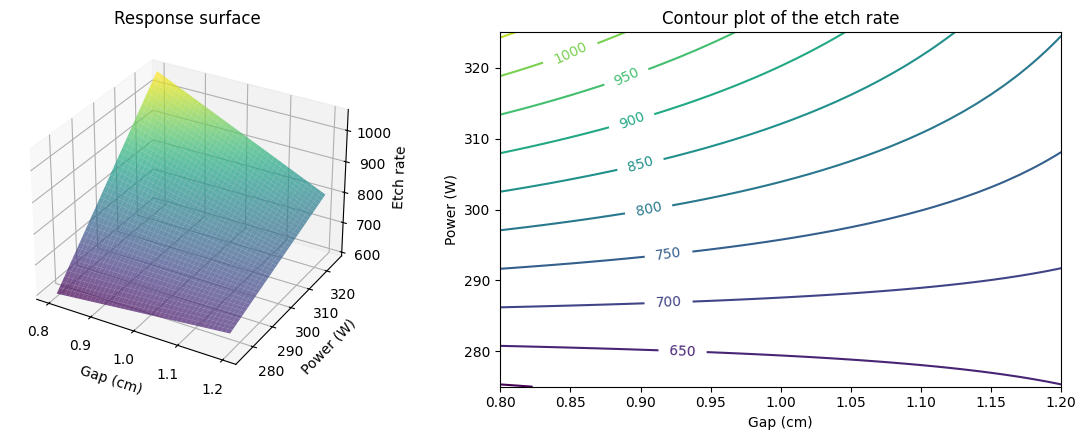

In [15]:
red_nat = smf.ols("etch ~ gap * power", data=etch).fit()
print(red_nat.params)

g1, g2 = np.meshgrid(np.linspace(0.8, 1.2, 41), np.linspace(275, 325, 41))
grid = pd.DataFrame({"gap": g1.ravel(), "power": g2.ravel()})
z = red_nat.predict(grid).to_numpy().reshape(g1.shape)

fig = plt.figure(figsize=(12, 4.5))
ax1 = fig.add_subplot(1, 2, 1, projection="3d")
ax1.plot_surface(g1, g2, z, cmap="viridis", alpha=0.7)
ax1.set(xlabel="Gap (cm)", ylabel="Power (W)", zlabel="Etch rate", title="Response surface")
ax2 = fig.add_subplot(1, 2, 2)
cs = ax2.contour(g1, g2, z, levels=np.arange(600, 1101, 50), cmap="viridis")
ax2.clabel(cs, fmt="%.0f")
ax2.set(xlabel="Gap (cm)", ylabel="Power (W)", title="Contour plot of the etch rate")
plt.tight_layout(); plt.show()

The interaction twists the plane, so the contour lines are curved. In natural units the coefficient of the gap is
$+4354.7$, although a larger gap decreases the etch rate everywhere in the region: with an interaction in the model it is the
slope at $Power = 0$ W. Interpret the coded model, use the natural one for predictions.

### Model adequacy

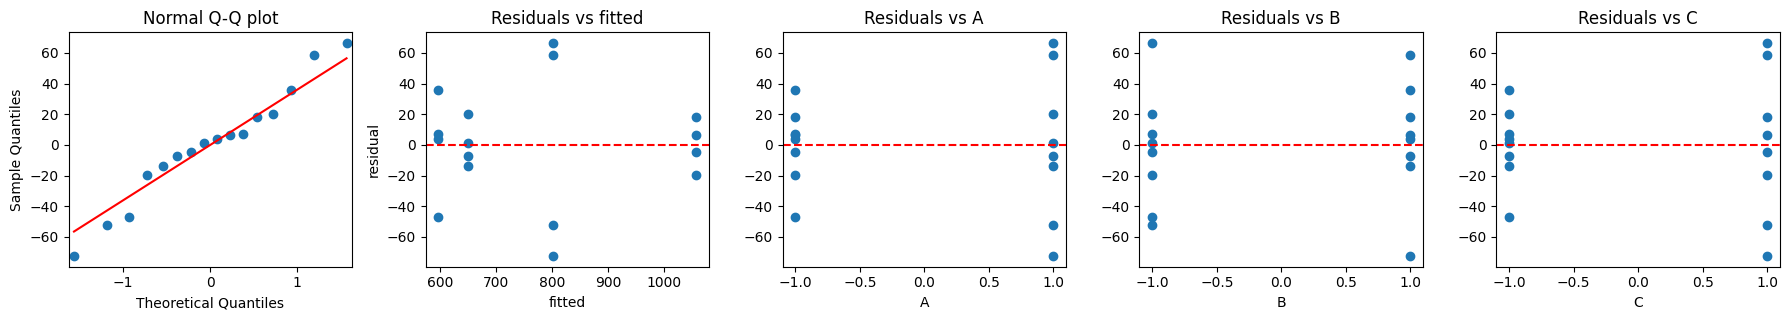

Shapiro-Wilk on residuals: ShapiroResult(statistic=np.float64(0.9696763407594419), pvalue=np.float64(0.8333388244618302))


In [16]:
residual_plots(red, etch, ["A", "B", "C"])

The normal Q-Q plot is acceptable and the residuals versus $B$ (not in the model) show no effect of the gas flow. But the
residuals versus the fitted values have a much larger spread at the fitted value of about 800, i.e. at high gap and high power.
Let us compare the variances in the four gap $\times$ power cells.

In [17]:
cells_AC = [d["etch"].to_numpy(dtype=float) for _, d in etch.groupby(["A", "C"])]
print(etch.groupby(["A", "C"])["etch"].agg(["mean", "std"]).round(1))
print(stats.levene(*cells_AC))
print(stats.bartlett(*cells_AC))

         mean   std
A  C               
-1 -1   597.0  34.5
    1  1056.8  16.2
 1 -1   649.0  14.7
    1   801.5  72.7
LeveneResult(statistic=np.float64(11.222047088956753), pvalue=np.float64(0.0008497048286857503))
BartlettResult(statistic=np.float64(8.558062513256084), pvalue=np.float64(0.03578204658179194))


The standard deviation at high gap and high power is about 73 Å/min, two to five times larger than in the other cells
(Levene $p < 0.001$). The conclusions about the means are not in danger (the effects are huge compared with the noise), but the
equal-variance assumption is violated and the gap may also affect the **variability** of the process (a dispersion effect,
Montgomery, Section 6.5 and Supplemental Material S6.5). In practice this would be a further argument for the small gap.

## 3. Generating a randomized $2^k$ design

`design_2k()` returns the design in standard order with a random run order. Map the codes to the real levels and add an empty
column for the response; sort by `run` to get the run sheet.

In [18]:
plan = design_2k(3, n_rep=2, names="ABC", seed=2026)
plan["gap_cm"] = plan["A"].map({-1: 0.8, 1: 1.2})
plan["flow_sccm"] = plan["B"].map({-1: 125, 1: 200})
plan["power_W"] = plan["C"].map({-1: 275, 1: 325})
plan["etch"] = np.nan                                   # to be filled in during the experiment
plan.sort_values("run")

,std_order,A,B,C,rep,run,gap_cm,flow_sccm,power_W,etch
5,6,1,-1,1,1,1,1.2,125,325,NaN
3,4,1,1,-1,1,2,1.2,200,275,NaN
4,5,-1,-1,1,1,3,0.8,125,325,NaN
10,3,-1,1,-1,2,4,0.8,200,275,NaN
14,7,-1,1,1,2,5,0.8,200,325,NaN
11,4,1,1,-1,2,6,1.2,200,275,NaN
2,3,-1,1,-1,1,7,0.8,200,275,NaN
13,6,1,-1,1,2,8,1.2,125,325,NaN
8,1,-1,-1,-1,2,9,0.8,125,275,NaN
6,7,-1,1,1,1,10,0.8,200,325,NaN


If each replicate is run on a different day (or with a different batch of material), randomize the order within each
replicate separately and analyse the replicates as blocks (Lecture 7).

## Assignment

Work on the assignment in class (in pairs, if you like). Whatever you do not finish in class, finish at home as homework.

* Run the notebook above and make sure you understand each step.
* Solve the following problems from Montgomery, *Design and Analysis of Experiments* (8th edition): **6.5, 6.1, 6.2, 6.3,
  6.44 and 6.45**; Problem 6.8 is optional. Problems 6.1-6.3 and 6.44 use the same data.
* For every test state the hypotheses, report the test statistic, its $p$-value and your decision; check the assumptions with
  residual plots; end each problem with a conclusion in one or two sentences.
* Submit your solved notebook as a pull request into the `HW/` folder of the course repository, named
  `HW/01NAEX_Ex05_HW_<Surname>.ipynb` (see `HW/README.md`). **Deadline: Sunday 1 November 2026** (the next lecture is on 2 November).

### Problem 6.5: router vibration

A router is used to cut locating notches on a printed circuit board. The vibration level at the surface of the board as it is
cut is considered to be a major source of dimensional variation in the notches. Two factors are thought to influence
vibration: bit size ($A$: 1/16 and 1/8 in.) and cutting speed ($B$: 40 and 90 rpm). Four boards are cut at each set of
conditions; the response is vibration measured as the resultant vector of three accelerometers.

| $A$ | $B$ | Treatment combination | I | II | III | IV |
|---|---|---|---|---|---|---|
| $-$ | $-$ | (1) | 18.2 | 18.9 | 12.9 | 14.4 |
| $+$ | $-$ | $a$ | 27.2 | 24.0 | 22.4 | 22.5 |
| $-$ | $+$ | $b$ | 15.9 | 14.5 | 15.1 | 14.2 |
| $+$ | $+$ | $ab$ | 41.0 | 43.9 | 36.3 | 39.9 |

In [19]:
router = pd.DataFrame({
    "A": np.repeat([-1, 1, -1, 1], 4),
    "B": np.repeat([-1, -1, 1, 1], 4),
    "vibration": [18.2, 18.9, 12.9, 14.4, 27.2, 24.0, 22.4, 22.5,
                  15.9, 14.5, 15.1, 14.2, 41.0, 43.9, 36.3, 39.9]})
router.pivot_table(index="B", columns="A", values="vibration", aggfunc=list)

A,-1,1
B,,
-1,"[18.2, 18.9, 12.9, 14.4]","[27.2, 24.0, 22.4, 22.5]"
1,"[15.9, 14.5, 15.1, 14.2]","[41.0, 43.9, 36.3, 39.9]"


**Problem 6.5**

(a) Estimate the factor effects. Which effects appear to be large?

(b) Use the analysis of variance to confirm your conclusions for part (a) ($\alpha = 0.05$).

(c) Construct a normal probability plot of the residuals and plot the residuals versus the predicted vibration level.
Interpret these plots.

(d) Draw the $AB$ interaction plot and interpret it. What levels of bit size and speed would you recommend for routine operation?

**Solution:**

**(a) Effects.** $2^2$ design with $n = 4$ replicates. Effect $= \text{Contrast}/(2n)$, $SS = \text{Contrast}^2/(4n)$, coded coefficient $=$ effect$/2$.

In [20]:
eff_r = effects_2k(router, "vibration", ["A", "B"])
display(eff_r.round(3))
print("Cell means (rows B = speed, columns A = bit size):")
display(router.pivot_table(index="B", columns="A", values="vibration").round(2))

,contrast,effect,SS,coef
term,,,,
A,133.1,16.638,1107.226,8.319
B,60.3,7.538,227.256,3.769
A:B,69.7,8.712,303.631,4.356


Cell means (rows B = speed, columns A = bit size):


A,-1,1
B,,
-1,16.10,24.02
1,14.92,40.28


Bit size $A = 16.6$ is by far the largest effect: the large bit raises the vibration by 16.6 units on average. The interaction $AB = 8.7$
and the speed $B = 7.5$ are also large compared with the run-to-run spread (standard deviations of 1 to 3 inside the cells). All three effects appear large.

In [21]:
# (b) ANOVA of the full model
m_r = smf.ols("vibration ~ A * B", data=router).fit()
display(sm.stats.anova_lm(m_r, typ=2))
print(f"MS_E = {m_r.mse_resid:.3f}, df_E = {m_r.df_resid:.0f}, R2 = {m_r.rsquared:.3f}")

,sum_sq,df,F,PR(>F)
A,1107.225625,1.0,185.251595,1.174669e-08
B,227.255625,1.0,38.022482,4.826292e-05
A:B,303.630625,1.0,50.800899,1.201078e-05
Residual,71.722500,12.0,NaN,NaN


MS_E = 5.977, df_E = 12, R2 = 0.958


**(b) ANOVA.** For each effect $H_0$: the effect is zero. $F$-tests with $(1, 12)$ df:
$A$: $F_0 = 185.3$, $P < 0.0001$. $B$: $F_0 = 38.0$, $P < 0.0001$. $AB$: $F_0 = 50.8$, $P < 0.0001$. All three are **rejected** at $\alpha = 0.05$,
which confirms (a). In a $2^k$ design the ANOVA carries the same information as the effects ($SS = \text{Contrast}^2/4n$), it only adds the
comparison with the error $MS_E = 5.98$. The model explains $R^2 = 95.8$ % of the variability.

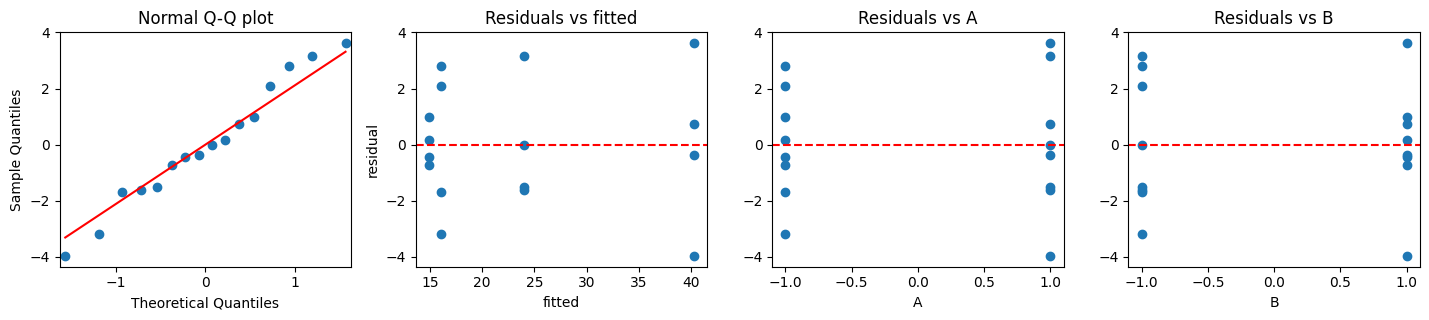

Shapiro-Wilk on residuals: ShapiroResult(statistic=np.float64(0.9714201580754169), pvalue=np.float64(0.8610570026553426))
cell standard deviations: {(-1, -1): 2.91, (-1, 1): 0.75, (1, -1): 2.24, (1, 1): 3.14}
Levene across the 4 cells: LeveneResult(statistic=np.float64(1.6315141061968699), pvalue=np.float64(0.23418514877072585))


In [22]:
# (c) residual plots: normal Q-Q, residuals vs fitted (predicted) vibration, residuals vs A and B
residual_plots(m_r, router, ["A", "B"])
print("cell standard deviations:", router.groupby(["A", "B"])["vibration"].std().round(2).to_dict())
print("Levene across the 4 cells:", stats.levene(*[g.to_numpy(float) for _, g in router.groupby(["A", "B"])["vibration"]]))

**(c)** The normal probability plot is close to a straight line and Shapiro-Wilk gives $p = 0.86$. The residuals versus the predicted vibration show no pattern.
The spread is smallest in the cell $b$ (sd 0.75) and largest in $ab$ (sd 3.1), but with four observations per cell this is not unusual (Levene $p = 0.23$).
The largest standardized residual is 1.6. The model is adequate.

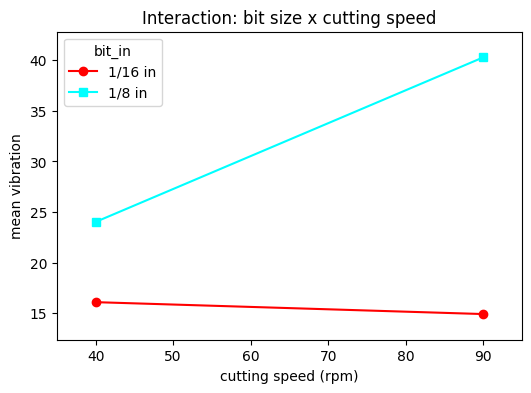

In [23]:
# (d) AB interaction plot in natural units
router["bit_in"] = router["A"].map({-1: "1/16 in", 1: "1/8 in"})
router["speed_rpm"] = router["B"].map({-1: 40, 1: 90})
fig, ax = plt.subplots(figsize=(6, 4))
interaction_plot(router["speed_rpm"], router["bit_in"], router["vibration"], markers=["o", "s"], ax=ax)
ax.set(xlabel="cutting speed (rpm)", ylabel="mean vibration", title="Interaction: bit size x cutting speed")
plt.show()

**(d)** The lines are not parallel. With the small bit (1/16 in) the speed hardly matters: 16.1 at 40 rpm and 14.9 at 90 rpm. With the large bit (1/8 in)
the vibration is higher and rises strongly with speed, from 24.0 to 40.3. The main effect of speed (+7.5) is therefore an average of "no effect" and
"a large effect", and only the interaction plot shows this.

**Recommendation.** Use the **small bit (1/16 in)**. The speed can then be chosen for productivity: **90 rpm**, where the vibration is even slightly lower
(14.9 against 16.1).

**Conclusion.** Bit size, speed and their interaction all affect vibration ($P < 0.0001$). The small bit gives low vibration at both speeds, the large bit at 90 rpm gives the worst.

### Problem 6.8 (optional): virus growth

A bacteriologist is interested in the effects of two different culture media and two different times on the growth of a
particular virus. Six replicates of a $2^2$ design are run in random order.

| Time (h) | Culture medium 1 | Culture medium 2 |
|---|---|---|
| 12 | 21, 22, 23, 28, 20, 26 | 25, 26, 24, 25, 29, 27 |
| 18 | 37, 39, 38, 38, 35, 36 | 31, 34, 29, 33, 30, 35 |

In [24]:
virus = pd.DataFrame({
    "medium": np.repeat([1, 2, 1, 2], 6),
    "time": np.repeat([12, 12, 18, 18], 6),
    "growth": [21, 22, 23, 28, 20, 26, 25, 26, 24, 25, 29, 27,
               37, 39, 38, 38, 35, 36, 31, 34, 29, 33, 30, 35]})
virus.pivot_table(index="time", columns="medium", values="growth", aggfunc="mean")

medium,1,2
time,,
12,23.333333,26.0
18,37.166667,32.0


**Problem 6.8 (optional).** Analyse the data and draw appropriate conclusions. Is the effect of time the same for both media?
Analyse the residuals and comment on the model's adequacy.

**Solution:**

**Coding.** $A$ = culture medium ($-1$: medium 1, $+1$: medium 2), $B$ = time ($-1$: 12 h, $+1$: 18 h), $n = 6$.
$H_0$: the effect is zero, for $A$, $B$ and $AB$, $F$-tests with $(1, 20)$ df.

,contrast,effect,SS,coef
term,,,,
A,-15,-1.250,9.375,-0.625
B,119,9.917,590.042,4.958
A:B,-47,-3.917,92.042,-1.958


,sum_sq,df,F,PR(>F)
A,9.375000,1.0,1.835237,1.906172e-01
B,590.041667,1.0,115.505710,9.290525e-10
A:B,92.041667,1.0,18.017945,3.969387e-04
Residual,102.166667,20.0,NaN,NaN


Cell means:


medium,1,2
time,,
12,23.33,26.0
18,37.17,32.0


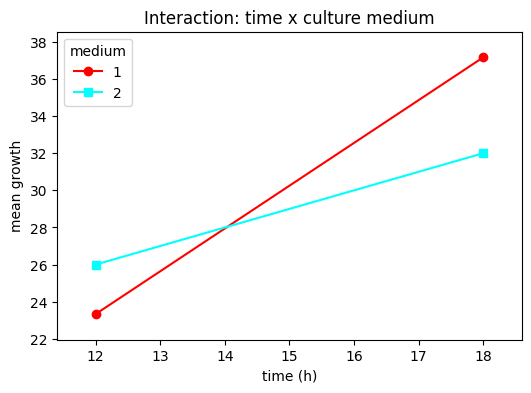

In [25]:
virus["A"] = virus["medium"].map({1: -1, 2: 1})
virus["B"] = virus["time"].map({12: -1, 18: 1})
display(effects_2k(virus, "growth", ["A", "B"]).round(3))

m_v = smf.ols("growth ~ A * B", data=virus).fit()
display(sm.stats.anova_lm(m_v, typ=2))
print("Cell means:")
display(virus.pivot_table(index="time", columns="medium", values="growth").round(2))

fig, ax = plt.subplots(figsize=(6, 4))
interaction_plot(virus["time"], virus["medium"], virus["growth"], markers=["o", "s"], ax=ax)
ax.set(xlabel="time (h)", ylabel="mean growth", title="Interaction: time x culture medium")
plt.show()

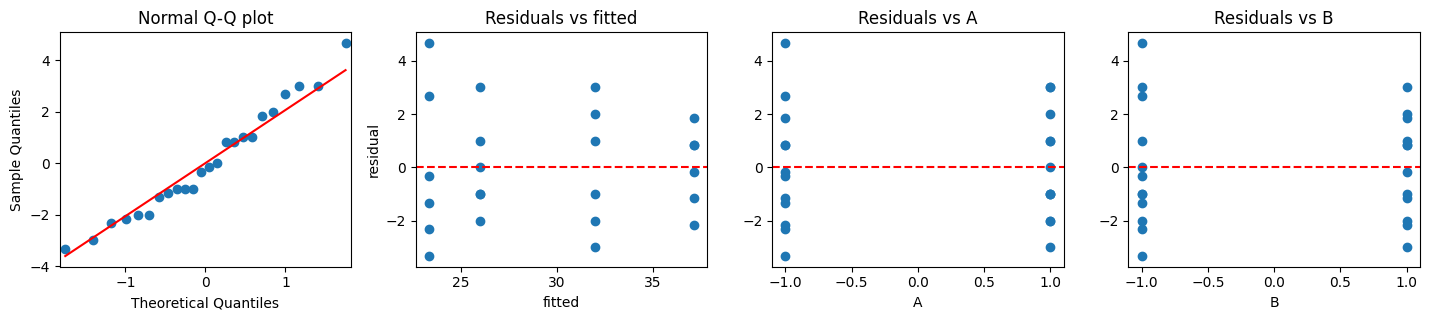

Shapiro-Wilk on residuals: ShapiroResult(statistic=np.float64(0.9661561875494007), pvalue=np.float64(0.5736956762158621))
Levene across the 4 cells: LeveneResult(statistic=np.float64(1.102693602693603), pvalue=np.float64(0.37122235454966696))


In [26]:
residual_plots(m_v, virus, ["A", "B"])
print("Levene across the 4 cells:", stats.levene(*[g.to_numpy(float) for _, g in virus.groupby(["medium", "time"])["growth"]]))

Time: $F_0 = 115.5$, $P < 0.0001$, **rejected**. Interaction: $F_0 = 18.0$, $P = 0.0004$, **rejected**. Medium: $F_0 = 1.8$, $P = 0.19$, not rejected.

**The effect of time is not the same for both media.** In medium 1 the growth rises from 23.3 to 37.2 ($+13.8$), in medium 2 only from 26.0 to 32.0 ($+6.0$).
The lines cross: at 12 h medium 2 is slightly higher, at 18 h medium 1 is clearly higher. The main effect of the medium ($-1.25$, not significant) is the average
of $+2.7$ and $-5.2$ and says nothing useful on its own.

Residuals: Q-Q plot close to a line, Shapiro-Wilk $p = 0.57$, similar spread in the four cells (Levene $p = 0.37$). The model is adequate.

**Conclusion.** Growth increases with time, much more in medium 1 than in medium 2. For long cultures (18 h) medium 1 is better, for short ones (12 h) the media are about equal.

### Problem 6.1: tool life

An engineer is interested in the effects of cutting speed ($A$), tool geometry ($B$), and cutting angle ($C$) on the life
(in hours) of a machine tool. Two levels of each factor are chosen, and three replicates of a $2^3$ factorial design are run.
The results are as follows:

| $A$ | $B$ | $C$ | Treatment combination | I | II | III |
|---|---|---|---|---|---|---|
| $-$ | $-$ | $-$ | (1) | 22 | 31 | 25 |
| $+$ | $-$ | $-$ | $a$ | 32 | 43 | 29 |
| $-$ | $+$ | $-$ | $b$ | 35 | 34 | 50 |
| $+$ | $+$ | $-$ | $ab$ | 55 | 47 | 46 |
| $-$ | $-$ | $+$ | $c$ | 44 | 45 | 38 |
| $+$ | $-$ | $+$ | $ac$ | 40 | 37 | 36 |
| $-$ | $+$ | $+$ | $bc$ | 60 | 50 | 54 |
| $+$ | $+$ | $+$ | $abc$ | 39 | 41 | 47 |

In [27]:
tool = pd.read_csv(URL + "Problem_6_1.txt", sep=";")
tool.columns = ["A", "B", "C", "life"]        # cutting speed, tool geometry, cutting angle; life in hours
tool.pivot_table(index=["C", "B"], columns="A", values="life", aggfunc=list)

A                -1             1
C  B                             
-1 -1  [22, 31, 25]  [32, 43, 29]
    1  [35, 34, 50]  [55, 47, 46]
 1 -1  [44, 45, 38]  [40, 37, 36]
    1  [60, 50, 54]  [39, 41, 47]

**Problem 6.1**

(a) Estimate the factor effects. Which effects appear to be large?

(b) Use the analysis of variance to confirm your conclusions for part (a).

(c) Write down a regression model for predicting tool life (in hours) based on the results of this experiment.

(d) Analyze the residuals. Are there any obvious problems?

(e) On the basis of an analysis of main effect and interaction plots, what coded factor levels of $A$, $B$, and $C$ would
you recommend using?

**Solution:**

**(a) Effects.** $2^3$ design, $n = 3$ replicates. Effect $= \text{Contrast}/(4n)$, $SS = \text{Contrast}^2/(8n)$.

In [28]:
eff_t = effects_2k(tool, "life", ["A", "B", "C"])
display(eff_t.round(3))
print("Effects sorted by size:")
print(eff_t["effect"].reindex(eff_t["effect"].abs().sort_values(ascending=False).index).round(2).to_string())

,contrast,effect,SS,coef
term,,,,
A,4,0.333,0.667,0.167
B,136,11.333,770.667,5.667
A:B,-20,-1.667,16.667,-0.833
C,82,6.833,280.167,3.417
A:C,-106,-8.833,468.167,-4.417
B:C,-34,-2.833,48.167,-1.417
A:B:C,-26,-2.167,28.167,-1.083


Effects sorted by size:
term
B        11.33
A:C      -8.83
C         6.83
B:C      -2.83
A:B:C    -2.17
A:B      -1.67
A         0.33


Three effects stand out: **tool geometry $B = +11.3$ h**, the **interaction $AC = -8.8$ h** and the **cutting angle $C = +6.8$ h**.
The others are small: $BC = -2.8$, $ABC = -2.2$, $AB = -1.7$ and the main effect of the cutting speed $A = +0.3$ h, which is practically zero.

In [29]:
# (b) ANOVA of the full model; MS_E with 16 df is the pure error
full_t = smf.ols("life ~ A * B * C", data=tool).fit()
display(sm.stats.anova_lm(full_t, typ=2))
print(f"MS_E = {full_t.mse_resid:.3f}, df_E = {full_t.df_resid:.0f}, R2 = {full_t.rsquared:.3f}, adj. R2 = {full_t.rsquared_adj:.3f}")

,sum_sq,df,F,PR(>F)
A,0.666667,1.0,0.022099,0.883680
B,770.666667,1.0,25.546961,0.000117
A:B,16.666667,1.0,0.552486,0.468078
C,280.166667,1.0,9.287293,0.007679
A:C,468.166667,1.0,15.519337,0.001172
B:C,48.166667,1.0,1.596685,0.224475
A:B:C,28.166667,1.0,0.933702,0.348282
Residual,482.666667,16.0,NaN,NaN


MS_E = 30.167, df_E = 16, R2 = 0.770, adj. R2 = 0.669


**(b) ANOVA.** $H_0$: the effect is zero, for each of the seven effects, $F$-tests with $(1, 16)$ df.
$B$: $F_0 = 25.5$, $P = 0.0001$. $AC$: $F_0 = 15.5$, $P = 0.001$. $C$: $F_0 = 9.3$, $P = 0.008$. These three are **rejected**.
$A$ ($P = 0.88$), $AB$ ($P = 0.47$), $BC$ ($P = 0.22$) and $ABC$ ($P = 0.35$) are not. This is exactly the picture of (a).

In [30]:
# (c) reduced model: B, C, AC and, for hierarchy, the main effect A
red_t = smf.ols("life ~ A + B + C + A:C", data=tool).fit()
print(red_t.summary().tables[1])
print(f"\nMS_E = {red_t.mse_resid:.3f}, df_E = {red_t.df_resid:.0f}, R2 = {red_t.rsquared:.3f}, adj. R2 = {red_t.rsquared_adj:.3f}")
print("\nLack of fit of the reduced model (dropped terms AB, BC, ABC against the pure error):")
display(sm.stats.anova_lm(red_t, full_t))

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     40.8333      1.124     36.342      0.000      38.482      43.185
A              0.1667      1.124      0.148      0.884      -2.185       2.518
B              5.6667      1.124      5.043      0.000       3.315       8.018
C              3.4167      1.124      3.041      0.007       1.065       5.768
A:C           -4.4167      1.124     -3.931      0.001      -6.768      -2.065

MS_E = 30.298, df_E = 19, R2 = 0.725, adj. R2 = 0.667

Lack of fit of the reduced model (dropped terms AB, BC, ABC against the pure error):


,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,19.0,575.666667,0.0,NaN,NaN,NaN
1,16.0,482.666667,3.0,93.0,1.027624,0.406692


**(c) Regression model** in coded variables ($x_1$ = speed, $x_2$ = geometry, $x_3$ = angle, each $\pm 1$):

$$\hat y = 40.83 + 0.17\,x_1 + 5.67\,x_2 + 3.42\,x_3 - 4.42\,x_1 x_3 \quad \text{(hours)}$$

The coefficients are one half of the effects. The main effect of $A$ is kept only because $AC$ is in the model (hierarchy principle, see Problem 6.44).
The lack of fit of the reduced model is not significant ($F_0 = 1.03$ on $(3, 16)$ df, $P = 0.41$), so the dropped terms are noise and the model is adequate.

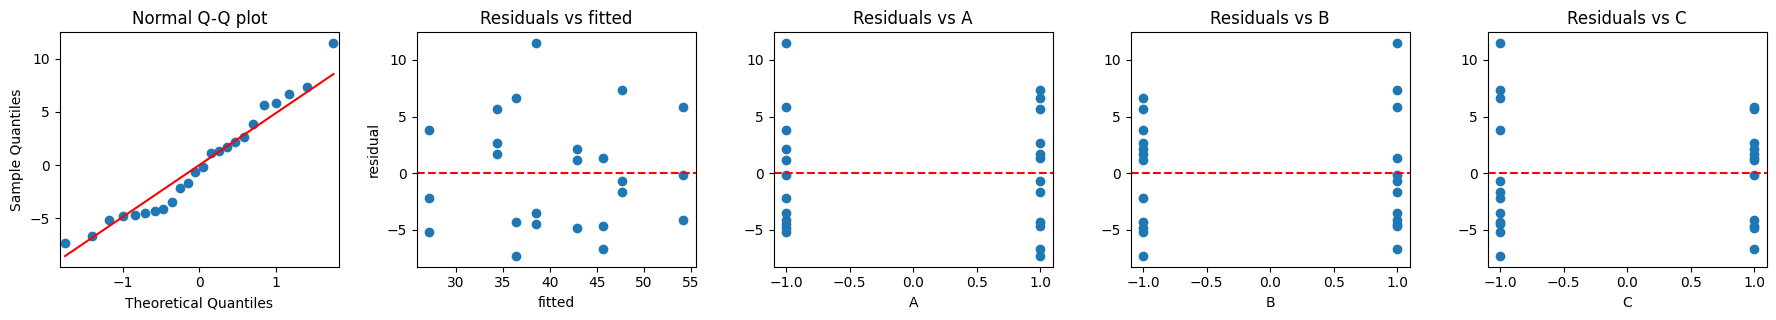

Shapiro-Wilk on residuals: ShapiroResult(statistic=np.float64(0.9530015025955682), pvalue=np.float64(0.31429112905947987))
largest standardized residual: 2.09


In [31]:
# (d) residual analysis of the reduced model
residual_plots(red_t, tool, ["A", "B", "C"])
print(f"largest standardized residual: {(red_t.resid / np.sqrt(red_t.mse_resid)).abs().max():.2f}")

**(d)** The normal probability plot is acceptable (Shapiro-Wilk $p = 0.31$), the residuals show no pattern against the fitted values or against any factor,
and the spread is similar at both levels of every factor. The largest standardized residual is 2.1 (the value 50 h in the combination $b$, replicate III),
which is not an outlier in 24 observations. No obvious problems.

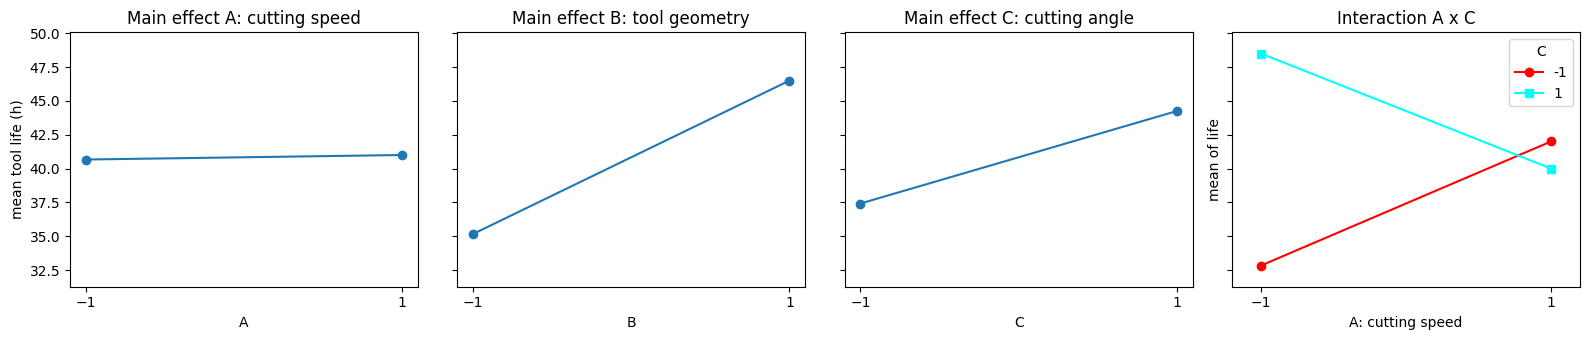

Mean life in the A x C cells (rows C, columns A):


A,-1,1
C,,
-1,32.83,42.0
1,48.50,40.0


Mean life at the 8 corners:


mean life
A  B  C            
-1 -1 -1      26.00
       1      42.33
    1 -1      39.67
       1      54.67
 1 -1 -1      34.67
       1      37.67
    1 -1      49.33
       1      42.33

In [32]:
# (e) main effect plots and the A x C interaction
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True)
for ax, f, name in zip(axes[:3], ["A", "B", "C"], ["A: cutting speed", "B: tool geometry", "C: cutting angle"]):
    means = tool.groupby(f)["life"].mean()
    ax.plot(means.index, means.values, "o-"); ax.set(xlabel=f, title=f"Main effect {name}", xticks=[-1, 1])
axes[0].set_ylabel("mean tool life (h)")
interaction_plot(tool["A"], tool["C"], tool["life"], markers=["o", "s"], ax=axes[3])
axes[3].set(xlabel="A: cutting speed", title="Interaction A x C", xticks=[-1, 1])
plt.tight_layout(); plt.show()

print("Mean life in the A x C cells (rows C, columns A):")
display(tool.pivot_table(index="C", columns="A", values="life").round(2))
print("Mean life at the 8 corners:")
display(tool.groupby(["A", "B", "C"])["life"].mean().round(2).to_frame("mean life"))

**(e)** Tool geometry: the high level adds 11.3 h at every setting, so **$B = +1$**. Speed and angle must be read together because of the interaction:
at the low angle ($C = -1$) the high speed is better (42.0 vs 32.8 h), at the high angle ($C = +1$) the low speed is better (48.5 vs 40.0 h).
The best pair is **$A = -1$, $C = +1$**. The recommended corner is $(A, B, C) = (-1, +1, +1)$ with a predicted life of
$40.83 - 0.17 + 5.67 + 3.42 + 4.42 = 54.2$ h (observed mean of that cell: 54.7 h).

**Conclusion.** Tool life depends on the geometry ($+11.3$ h) and on the speed $\times$ angle combination. Use the high geometry, the high cutting angle and the low cutting speed.

**Problem 6.2.** Reconsider part (c) of Problem 6.1. Use the regression model to generate response surface and contour plots
of the tool life response. Interpret these plots. Do they provide insight regarding the desirable operating conditions for
this process? (The problem gives no natural levels, so draw the plots in the coded variables; with three factors fix the
third one at $-1$ and at $+1$.)

**Solution:**

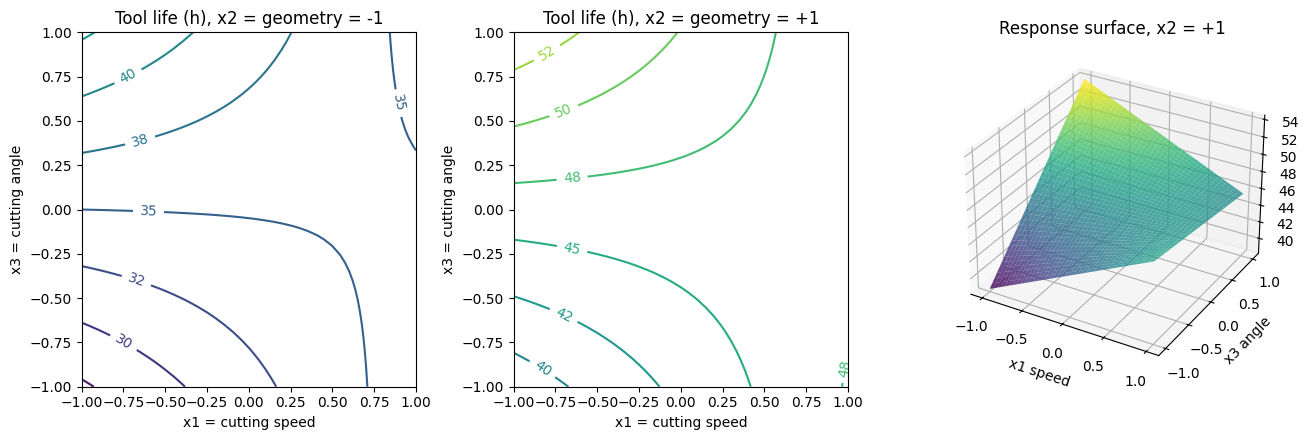

In [33]:
# Response surface and contour plots of the reduced model in coded variables.
# The interaction is between x1 (speed) and x3 (angle), so these are the axes; x2 (geometry) only shifts the surface, we fix it at -1 and +1.
g1, g3 = np.meshgrid(np.linspace(-1, 1, 41), np.linspace(-1, 1, 41))

fig = plt.figure(figsize=(13, 4.5))
for i, x2 in enumerate([-1, 1]):
    grid = pd.DataFrame({"A": g1.ravel(), "B": x2, "C": g3.ravel()})
    z = red_t.predict(grid).to_numpy().reshape(g1.shape)
    ax = fig.add_subplot(1, 3, i + 1)
    cs = ax.contour(g1, g3, z, levels=np.arange(25, 60, 2.5), cmap="viridis")
    ax.clabel(cs, fmt="%.0f")
    ax.set(xlabel="x1 = cutting speed", ylabel="x3 = cutting angle", title=f"Tool life (h), x2 = geometry = {x2:+d}")
grid = pd.DataFrame({"A": g1.ravel(), "B": 1, "C": g3.ravel()})
z = red_t.predict(grid).to_numpy().reshape(g1.shape)
ax = fig.add_subplot(1, 3, 3, projection="3d")
ax.plot_surface(g1, g3, z, cmap="viridis", alpha=0.8)
ax.set(xlabel="x1 speed", ylabel="x3 angle", zlabel="life (h)", title="Response surface, x2 = +1")
plt.tight_layout(); plt.show()

Because of the $x_1 x_3$ term the fitted surface is a **twisted plane** and the contour lines are curves, not parallel lines. The two panels have the same
shape: tool geometry enters only additively and lifts the whole surface by $11.3$ h from $x_2 = -1$ to $x_2 = +1$.

Reading the $x_2 = +1$ panel: the longest life is in the top-left corner, **low speed and high angle** (54 h). Moving along the angle axis matters a lot at low speed
($38.5 \to 54.2$ h) and almost not at all at high speed ($47.7 \to 45.7$ h). Moving along the speed axis helps at the low angle and hurts at the high angle.

**Insight for operation.** The best conditions are $x_1 = -1$, $x_2 = +1$, $x_3 = +1$, as in 6.1(e). The plots add one thing the ANOVA does not show: at high speed
the life is insensitive to the angle (about 46-48 h), so if a high speed is needed for throughput, the angle need not be controlled tightly, at a cost of about 7 h of tool life.

**Problem 6.3.** Find the standard error of the factor effects and approximate 95 percent confidence limits for the factor
effects in Problem 6.1. Do the results of this analysis agree with the conclusions from the analysis of variance?

**Solution:**

In [34]:
# standard error of an effect: V(effect) = sigma^2 / (n 2^(k-2)), sigma^2 estimated by MS_E of the full model (16 df)
n, k = 3, 3
se_eff = np.sqrt(full_t.mse_resid / (n * 2**(k - 2)))
t_crit = stats.t.ppf(0.975, full_t.df_resid)
print(f"MS_E = {full_t.mse_resid:.3f}, se(effect) = {se_eff:.3f}, t_0.975({full_t.df_resid:.0f}) = {t_crit:.3f}, half-width = {t_crit * se_eff:.3f} h")

ci_t = 2 * full_t.conf_int().drop("Intercept")              # effects = 2 x coded coefficients
ci_t.columns = ["lower", "upper"]
ci_t.insert(0, "effect", 2 * full_t.params.drop("Intercept"))
ci_t["excludes 0"] = (ci_t["lower"] > 0) | (ci_t["upper"] < 0)
display(ci_t.round(3))

MS_E = 30.167, se(effect) = 2.242, t_0.975(16) = 2.120, half-width = 4.753 h


,effect,lower,upper,excludes 0
A,0.333,-4.420,5.087,False
B,11.333,6.580,16.087,True
A:B,-1.667,-6.420,3.087,False
C,6.833,2.080,11.587,True
A:C,-8.833,-13.587,-4.080,True
B:C,-2.833,-7.587,1.920,False
A:B:C,-2.167,-6.920,2.587,False


$se(\text{effect}) = \sqrt{MS_E / (n\,2^{k-2})} = \sqrt{30.17 / 6} = 2.24$ h, and with $t_{0.025,16} = 2.12$ every effect has the 95 % interval
effect $\pm 4.75$ h.

Three intervals exclude zero: $B$ $(6.6,\ 16.1)$, $C$ $(2.1,\ 11.6)$ and $AC$ $(-13.6,\ -4.1)$. The other four contain zero.
This agrees exactly with the ANOVA, and it must: the $t$-test of a coefficient and the $F$-test of the same effect with 1 df are the same test ($F = t^2$).
The intervals add the size: tool geometry is worth 7 to 16 hours, the angle 2 to 12 hours.

**Problem 6.44: hierarchical models.** Several times we have used the hierarchy principle in selecting a model; that is,
we have included nonsignificant lower order terms in a model because they were factors involved in significant higher order
terms. Hierarchy is certainly not an absolute principle that must be followed in all cases. To illustrate, consider the
model resulting from Problem 6.1, which required that a nonsignificant main effect be included to achieve hierarchy. Using the
data from Problem 6.1:

(a) Fit both the hierarchical and the nonhierarchical models.

(b) Calculate the PRESS statistic, the adjusted $R^2$, and the mean square error for both models.
(PRESS $= \sum_i \left(e_i / (1 - h_{ii})\right)^2$; the leverages $h_{ii}$ are in `model.get_influence().hat_matrix_diag`.)

(c) Find a 95 percent confidence interval on the estimate of the mean response at a cube corner
($x_1 = x_2 = x_3 = \pm 1$). Hint: `model.get_prediction(new_data).summary_frame()`; compare with
$V(\hat y) = \sigma^2 \sum_j x_j^2 / (n2^k)$ (sum over the terms in the model, including the intercept).

(d) Based on the analyses you have conducted, which model do you prefer?

**Solution:**

In [35]:
# (a) hierarchical (A, B, C, AC) and nonhierarchical (B, C, AC) models
hier = smf.ols("life ~ A + B + C + A:C", data=tool).fit()
nonhier = smf.ols("life ~ B + C + A:C", data=tool).fit()
print("hierarchical:    ", hier.params.round(3).to_dict())
print("nonhierarchical: ", nonhier.params.round(3).to_dict())

# (b) PRESS, adjusted R2 and MS_E
def press(model):
    h = model.get_influence().hat_matrix_diag
    return float(np.sum((model.resid / (1 - h))**2))

comp = pd.DataFrame({
    "terms": [len(hier.params), len(nonhier.params), len(full_t.params)],
    "df_E": [hier.df_resid, nonhier.df_resid, full_t.df_resid],
    "PRESS": [press(hier), press(nonhier), press(full_t)],
    "adj. R2": [hier.rsquared_adj, nonhier.rsquared_adj, full_t.rsquared_adj],
    "MS_E": [hier.mse_resid, nonhier.mse_resid, full_t.mse_resid],
}, index=["hierarchical", "nonhierarchical", "full"])
display(comp.round(3))

hierarchical:     {'Intercept': 40.833, 'A': 0.167, 'B': 5.667, 'C': 3.417, 'A:C': -4.417}
nonhierarchical:  {'Intercept': 40.833, 'B': 5.667, 'C': 3.417, 'A:C': -4.417}


,terms,df_E,PRESS,adj. R2,MS_E
hierarchical,5,19.0,918.515,0.667,30.298
nonhierarchical,4,20.0,829.920,0.684,28.817
full,8,16.0,1086.000,0.669,30.167


**(a), (b)** The coefficients of $B$, $C$ and $AC$ are identical in both models (orthogonal design), the nonhierarchical model only drops $\hat\beta_1 = 0.17$.

| | PRESS | adj. $R^2$ | $MS_E$ |
|---|---|---|---|
| hierarchical | 918.5 | 0.667 | 30.30 (19 df) |
| nonhierarchical | 829.9 | 0.684 | 28.82 (20 df) |

The nonhierarchical model is slightly better on all three criteria. The term $A$ explains almost nothing ($SS_A = 0.67$) but costs one degree of freedom,
so removing it lowers $MS_E$ and PRESS (the prediction error estimated by leave-one-out).

In [36]:
# (c) 95 % confidence interval for the mean response at cube corners
corners = pd.DataFrame({"A": [1, -1, 1, -1], "B": [1, 1, 1, 1], "C": [1, 1, -1, -1]})
for name, model in [("hierarchical", hier), ("nonhierarchical", nonhier)]:
    p = len(model.params)
    sf = model.get_prediction(corners).summary_frame(alpha=0.05)
    print(f"{name}: se(y_hat) from the formula sqrt(MS_E * p / (n 2^k)) = sqrt({model.mse_resid:.2f} * {p} / 24) = {np.sqrt(model.mse_resid * p / 24):.3f}")
    display(pd.concat([corners, sf[["mean", "mean_se", "mean_ci_lower", "mean_ci_upper"]].round(3)], axis=1))

hierarchical: se(y_hat) from the formula sqrt(MS_E * p / (n 2^k)) = sqrt(30.30 * 5 / 24) = 2.512


,A,B,C,mean,mean_se,mean_ci_lower,mean_ci_upper
0,1,1,1,45.667,2.512,40.408,50.925
1,-1,1,1,54.167,2.512,48.908,59.425
2,1,1,-1,47.667,2.512,42.408,52.925
3,-1,1,-1,38.500,2.512,33.241,43.759


nonhierarchical: se(y_hat) from the formula sqrt(MS_E * p / (n 2^k)) = sqrt(28.82 * 4 / 24) = 2.192


,A,B,C,mean,mean_se,mean_ci_lower,mean_ci_upper
0,1,1,1,45.500,2.192,40.929,50.071
1,-1,1,1,54.333,2.192,49.762,58.905
2,1,1,-1,47.500,2.192,42.929,52.071
3,-1,1,-1,38.667,2.192,34.095,43.238


**(c)** At every corner $x_j^2 = 1$, so $V(\hat y) = \sigma^2 p / (n 2^k)$ with $p$ the number of terms including the intercept.
Hierarchical: $se = \sqrt{30.30 \cdot 5 / 24} = 2.51$, nonhierarchical: $se = \sqrt{28.82 \cdot 4 / 24} = 2.19$, both equal to what `get_prediction()` reports.
At the recommended corner $(-1, +1, +1)$ the intervals are $(48.9,\ 59.4)$ h and $(49.8,\ 58.9)$ h: the nonhierarchical interval is about 13 % shorter,
because it has one parameter less to estimate and a smaller $MS_E$. The point estimates differ by only $0.17$ h.

**(d) Preferred model.** For these data I prefer the **nonhierarchical model** $\hat y = 40.83 + 5.67\,x_2 + 3.42\,x_3 - 4.42\,x_1 x_3$:
the main effect of $A$ is zero for all practical purposes ($0.33$ h, $P = 0.88$), and dropping it gives a smaller PRESS, a smaller $MS_E$ and narrower prediction intervals.

The price is interpretability. A model with $x_1 x_3$ but without $x_1$ is not invariant to a shift of the origin of $x_3$: rewriting the cutting angle in natural units
($x_3 = (\text{angle} - \text{centre})/\text{half-range}$) would generate an $x_1$ term that the model does not contain. In coded variables, for prediction inside the design region,
this does not matter. If the model is to be reported in natural units, keep the hierarchical one. The differences are small either way, which is the point of the problem:
hierarchy is a guideline, not a law.

**Problem 6.45.** Suppose that you want to run a $2^3$ factorial design. The variance of an individual observation is
expected to be about 4. Suppose that you want the length of a 95 percent confidence interval on any effect to be less than or
equal to 1.5. How many replicates of the design do you need to run? (Use the $t$ quantile with the error degrees of freedom
of the full model, $2^k(n-1)$, and compare with the normal approximation.)

**Solution:**

In [37]:
k, sigma2, max_length = 3, 4.0, 1.5
rows = []
for n in range(2, 21):
    se = np.sqrt(sigma2 / (n * 2**(k - 2)))                 # standard error of an effect
    df = 2**k * (n - 1)                                      # error df of the full model
    rows.append({"n": n, "runs": n * 2**k, "df_E": df, "se(effect)": se,
                 "length (t)": 2 * stats.t.ppf(0.975, df) * se, "length (normal)": 2 * 1.96 * se})
tab = pd.DataFrame(rows).set_index("n")
display(tab.round(3))
n_t = tab.index[tab["length (t)"] <= max_length][0]
n_z = tab.index[tab["length (normal)"] <= max_length][0]
print(f"smallest n with length <= {max_length}: t quantile -> n = {n_t}, normal approximation -> n = {n_z}")
print(f"normal approximation directly: n >= 2 (1.96 / 0.75)^2 = {2 * (1.96 / 0.75)**2:.2f}")

,runs,df_E,se(effect),length (t),length (normal)
n,,,,,
2,16,8,1.000,4.612,3.920
3,24,16,0.816,3.462,3.201
4,32,24,0.707,2.919,2.772
5,40,32,0.632,2.577,2.479
6,48,40,0.577,2.334,2.263
7,56,48,0.535,2.149,2.095
8,64,56,0.500,2.003,1.960
9,72,64,0.471,1.883,1.848
10,80,72,0.447,1.783,1.753


smallest n with length <= 1.5: t quantile -> n = 14, normal approximation -> n = 14
normal approximation directly: n >= 2 (1.96 / 0.75)^2 = 13.66


The variance of an effect is $V(\text{effect}) = 4\sigma^2 / (n 2^k) = 2/n$ for $\sigma^2 = 4$ and $k = 3$, and the 95 % interval has length
$2\,t_{0.025,\,8(n-1)}\sqrt{2/n}$. We need it to be at most 1.5, that is a half-width of 0.75.

Normal approximation: $n \ge 2(1.96/0.75)^2 = 13.7$, so $n = 14$. With the exact $t$ quantile: $n = 13$ gives a length of 1.56, $n = 14$ gives 1.50
($t_{0.025,104} = 1.98$). Both lead to **$n = 14$ replicates**, i.e. $14 \cdot 8 = 112$ runs. The normal approximation is good here because the error
degrees of freedom are large (over 100). It would be optimistic for small $n$: at $n = 2$ the $t$-based length is 4.6 against 3.9 from the normal.

**Conclusion.** To estimate every effect to $\pm 0.75$ with 95 % confidence when $\sigma = 2$, run 14 replicates of the $2^3$ design (112 runs).
The required $n$ grows with $(\sigma / \text{half-width})^2$: this precision target is $0.375\,\sigma$, which is demanding.